In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All"
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')
np.random.seed(42)

/kaggle/input/notebooks/dhyeybuch/football-xg-dataset-build/__notebook__.ipynb
/kaggle/input/notebooks/dhyeybuch/football-xg-dataset-build/__output__.json
/kaggle/input/notebooks/dhyeybuch/football-xg-dataset-build/__results__.html
/kaggle/input/notebooks/dhyeybuch/football-xg-dataset-build/custom.css
/kaggle/input/notebooks/dhyeybuch/football-xg-dataset-build/statsbomb_shots_2015_16.csv


In [2]:
import json
import matplotlib.pyplot as plt
from xgboost import XGBClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import log_loss, roc_auc_score

In [3]:
# StatsBomb open data, 2015/16 season - Premier League, La Liga, Serie A, Ligue 1. One row per shot
df = pd.read_csv('/kaggle/input/notebooks/dhyeybuch/football-xg-dataset-build/statsbomb_shots_2015_16.csv')

In [4]:
df.head(n=10)

,match_id,competition,match_date,home_team,away_team,shot_id,team,player,position,period,...,follows_dribble,aerial_won,redirect,deflected,end_location_x,end_location_y,end_location_z,statsbomb_xg,outcome,freeze_frame
0,3754217,Premier League,2015-09-19,Chelsea,Arsenal,9e0ee602-d62a-40fb-b34d-4431d2b0e52b,Arsenal,Aaron Ramsey,Right Wing,1,...,False,False,False,False,113.7,41.9,NaN,0.038832,Blocked,"[{""x"":107.2,""y"":45.2,""teammate"":false,""positio..."
1,3754217,Premier League,2015-09-19,Chelsea,Arsenal,94c49d0f-5fa9-4160-8449-1127b6370f33,Chelsea,Francesc Fàbregas i Soler,Right Defensive Midfield,1,...,False,False,False,False,117.0,40.5,0.2,0.031541,Saved,"[{""x"":93.2,""y"":46.9,""teammate"":false,""position..."
2,3754217,Premier League,2015-09-19,Chelsea,Arsenal,06f54bc7-10fd-4e08-b525-adb6d7bae3b4,Arsenal,Alexis Alejandro Sánchez Sánchez,Left Wing,1,...,False,False,False,False,120.0,30.2,0.1,0.006660,Off T,"[{""x"":82.8,""y"":24.4,""teammate"":false,""position..."
3,3754217,Premier League,2015-09-19,Chelsea,Arsenal,e8880b3f-7fc1-4305-b2d9-f115804b9f5c,Chelsea,Diego da Silva Costa,Center Forward,1,...,False,False,False,False,117.2,38.8,0.2,0.022902,Saved,"[{""x"":118.4,""y"":38.5,""teammate"":false,""positio..."
4,3754217,Premier League,2015-09-19,Chelsea,Arsenal,d83997d0-db73-4178-932e-3c311182bf81,Arsenal,Theo Walcott,Center Forward,1,...,False,False,False,False,115.7,36.7,0.5,0.049741,Saved,"[{""x"":103.4,""y"":46.0,""teammate"":false,""positio..."
5,3754217,Premier League,2015-09-19,Chelsea,Arsenal,5ae6cf10-8742-428c-be02-6a2ea2079436,Chelsea,Pedro Eliezer Rodríguez Ledesma,Right Wing,1,...,False,False,False,False,115.6,45.1,0.4,0.400975,Saved,"[{""x"":106.3,""y"":33.3,""teammate"":false,""positio..."
6,3754217,Premier League,2015-09-19,Chelsea,Arsenal,eefed603-e2b2-496e-90f0-dc4f77405678,Arsenal,Aaron Ramsey,Right Wing,1,...,False,False,False,False,120.0,72.8,1.4,0.023207,Off T,"[{""x"":111.1,""y"":17.7,""teammate"":false,""positio..."
7,3754217,Premier League,2015-09-19,Chelsea,Arsenal,d4b8afcd-88d7-45b7-90e6-179cf06d679d,Chelsea,Kurt Happy Zouma,Right Center Back,1,...,False,False,False,False,120.0,37.8,4.0,0.020538,Off T,"[{""x"":116.4,""y"":41.4,""teammate"":false,""positio..."
8,3754217,Premier League,2015-09-19,Chelsea,Arsenal,b6fb6606-663c-4671-96ce-c79c1d40d977,Chelsea,Pedro Eliezer Rodríguez Ledesma,Right Wing,1,...,False,False,False,False,120.0,46.6,1.6,0.033888,Off T,"[{""x"":100.0,""y"":29.7,""teammate"":false,""positio..."
9,3754217,Premier League,2015-09-19,Chelsea,Arsenal,f3f33c03-3b57-4116-bd01-ed067e37acef,Chelsea,Francesc Fàbregas i Soler,Right Defensive Midfield,1,...,False,False,False,False,101.2,31.0,NaN,0.026702,Blocked,"[{""x"":88.0,""y"":34.8,""teammate"":false,""position..."


In [5]:
print(df.shape)
print(df['competition'].value_counts())
df.columns

(37888, 32)
competition
Serie A           9998
Premier League    9908
La Liga           9168
Ligue 1           8814
Name: count, dtype: int64


Index(['match_id', 'competition', 'match_date', 'home_team', 'away_team',
       'shot_id', 'team', 'player', 'position', 'period', 'minute', 'second',
       'play_pattern', 'location_x', 'location_y', 'under_pressure',
       'shot_type', 'body_part', 'technique', 'first_time', 'one_on_one',
       'open_goal', 'follows_dribble', 'aerial_won', 'redirect', 'deflected',
       'end_location_x', 'end_location_y', 'end_location_z', 'statsbomb_xg',
       'outcome', 'freeze_frame'],
      dtype='object')

### Analysing the target `outcome`

In [6]:
df['outcome'].value_counts()

outcome
Off T               12637
Blocked              9472
Saved                8783
Goal                 3869
Wayward              2154
Post                  710
Saved Off Target      145
Saved to Post         118
Name: count, dtype: int64

In [7]:
df['is_goal'] = (df['outcome'] == 'Goal').astype(int)
print(f'Goal rate: {df["is_goal"].mean():.4f}')

# Only 1 in 10 shots is a goal, so accuracy is useless - saying "no goal" every time already gets 90%.
# I'll use log loss (the same loss Logistic Regression minimises, lower is better) and AUC (higher is better)

Goal rate: 0.1021


In [8]:
print(df['shot_type'].value_counts())
print()
print(df.groupby('shot_type')['is_goal'].mean())

shot_type
Open Play    35732
Free Kick     1749
Penalty        400
Corner           7
Name: count, dtype: int64

shot_type
Corner       0.428571
Free Kick    0.064608
Open Play    0.096636
Penalty      0.750000
Name: is_goal, dtype: float64


### Where are the shots taken from?

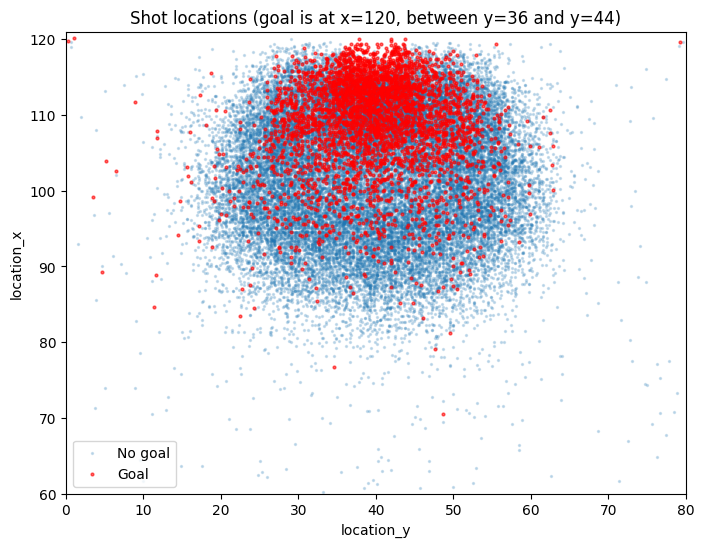

In [9]:
goals = df[df['is_goal'] == 1]
misses = df[df['is_goal'] == 0]

plt.figure(figsize=(8,6))
plt.scatter(misses['location_y'], misses['location_x'], s=2, alpha=0.2, label='No goal')
plt.scatter(goals['location_y'], goals['location_x'], s=4, alpha=0.6, color='red', label='Goal')
plt.xlim(0, 80)
plt.ylim(60, 121)
plt.xlabel("location_y")
plt.ylabel("location_x")
plt.title("Shot locations (goal is at x=120, between y=36 and y=44)")
plt.legend()
plt.show()

location_y
(0, 26]     0.029961
(26, 30]    0.062583
(30, 34]    0.089606
(34, 38]    0.143393
(38, 42]    0.187259
(42, 46]    0.129663
(46, 50]    0.094021
(50, 54]    0.064704
(54, 80]    0.020820
Name: is_goal, dtype: float64


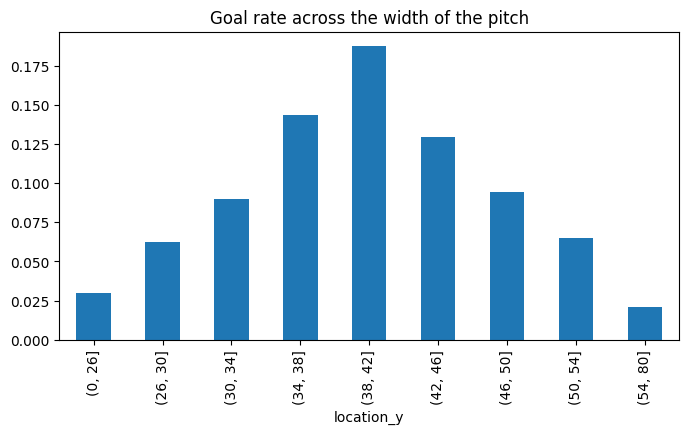

In [10]:
y_bins = pd.cut(df['location_y'], bins=[0, 26, 30, 34, 38, 42, 46, 50, 54, 80])
goal_rate_y = df.groupby(y_bins, observed=True)['is_goal'].mean()
print(goal_rate_y)

goal_rate_y.plot(kind='bar', figsize=(8,4), title='Goal rate across the width of the pitch')
plt.show()

# The goal rate peaks in the middle and drops on both sides.
# Logistic Regression gets one number for location_y so I don't think it can learn this shape. Trees should.

In [11]:
x_bins = pd.cut(df['location_x'], bins=[0, 90, 96, 102, 108, 114, 121])
print(df.groupby(x_bins, observed=True)['is_goal'].mean())

location_x
(0, 90]       0.013245
(90, 96]      0.025147
(96, 102]     0.048610
(102, 108]    0.109431
(108, 114]    0.155001
(114, 121]    0.253218
Name: is_goal, dtype: float64


In [12]:
print(df.groupby('body_part')['is_goal'].mean())
print()
print(df.groupby('body_part')['location_x'].mean())

# Headers score as often as shots with the foot?? Weird... but headers are taken much closer to goal, that must be why

body_part
Head          0.106950
Left Foot     0.093559
Other         0.356322
Right Foot    0.104674
Name: is_goal, dtype: float64

body_part
Head          111.455748
Left Foot     101.953103
Other         113.465517
Right Foot    101.369894
Name: location_x, dtype: float64


## Data Cleaning

In [13]:
df.isnull().sum()

match_id               0
competition            0
match_date             0
home_team              0
away_team              0
shot_id                0
team                   0
player                 0
position               0
period                 0
minute                 0
second                 0
play_pattern           0
location_x             0
location_y             0
under_pressure         0
shot_type              0
body_part              0
technique              0
first_time             0
one_on_one             0
open_goal              0
follows_dribble        0
aerial_won             0
redirect               0
deflected              0
end_location_x         0
end_location_y         0
end_location_z     11626
statsbomb_xg           0
outcome                0
freeze_frame           0
is_goal                0
dtype: int64

In [14]:
print(df['shot_id'].duplicated().sum())

0


In [15]:
print(df[(df['location_x'] > 120) | (df['location_y'] < 0) | (df['location_y'] > 80)][['location_x', 'location_y']])

# one shot is slightly past the goal line, just putting it back on the line
df['location_x'] = df['location_x'].clip(upper=120)

      location_x  location_y
2332       120.2         1.0


In [16]:
# Removing penalties (same spot every time, 75% go in - a completely different thing) and the few corner shots
print(f"{len(df)} -> ", end=" ")
df = df[df['shot_type'].isin(['Open Play', 'Free Kick'])].copy()
print(f"{len(df)}")

37888 ->  37481


In [17]:
# freeze_frame = where every visible player was standing when the shot was taken
print(json.loads(df['freeze_frame'].iloc[0])[:3])

[{'x': 107.2, 'y': 45.2, 'teammate': False, 'position': 'Left Back'}, {'x': 97.5, 'y': 43.8, 'teammate': False, 'position': 'Left Defensive Midfield'}, {'x': 100.9, 'y': 36.9, 'teammate': False, 'position': 'Right Wing'}]


In [18]:
# A few shots don't have the keeper in the freeze frame, removing them so I can use the keeper position later
df['keeper_in_frame'] = df['freeze_frame'].apply(lambda f: any(p['position'] == 'Goalkeeper' and not p['teammate'] for p in json.loads(f)))
print(f"{len(df)} -> ", end=" ")
df = df[df['keeper_in_frame']].copy()
print(f"{len(df)}")

37481 ->  37449


In [19]:
# Removing what we only know AFTER the shot (where it ended up, deflections) - that would be cheating
# statsbomb_xg is StatsBomb's own xG model, I am NOT using it as a feature, only keeping it to compare at the end
df = df.drop(columns=['end_location_x', 'end_location_y', 'end_location_z', 'deflected', 'redirect'])

## Splitting by match

In [20]:
# Same idea as the day split in Seoul bikes - all shots from one match go to the same set
matches = df[['match_id', 'competition']].drop_duplicates()

train_matches, remaining_matches = train_test_split(
    matches,
    test_size=0.4,
    random_state=42,
    stratify=matches['competition']
)

val_matches, test_matches = train_test_split(
    remaining_matches,
    test_size=0.5,
    random_state=42,
    stratify=remaining_matches['competition']
)

train_mask = df['match_id'].isin(train_matches['match_id'])
val_mask = df['match_id'].isin(val_matches['match_id'])
test_mask = df['match_id'].isin(test_matches['match_id'])

print(train_mask.sum(), val_mask.sum(), test_mask.sum())

22431 7501 7517


## Models on the clean data (no football knowledge yet)

In [21]:
# just the columns as they come, with one hot encoding for the categorical ones
features = ['location_x', 'location_y', 'minute', 'period', 'under_pressure', 'first_time', 'one_on_one',
            'open_goal', 'follows_dribble', 'aerial_won', 'body_part', 'technique', 'shot_type', 'play_pattern']

X_raw = pd.get_dummies(df[features], columns=['body_part', 'technique', 'shot_type', 'play_pattern'], drop_first=True, dtype=int)
y = df['is_goal']

X_train, y_train = X_raw[train_mask], y[train_mask]
X_val, y_val = X_raw[val_mask], y[val_mask]
X_test, y_test = X_raw[test_mask], y[test_mask]

In [22]:
# Trying different depths and checking log loss on validation - deep trees give silly 0/1 probabilities
for depth in range(2, 11):
    tree = DecisionTreeClassifier(max_depth=depth, min_samples_leaf=50, random_state=42)
    tree.fit(X_train, y_train)
    print(depth, round(log_loss(y_val, tree.predict_proba(X_val)[:, 1]), 4))

2 0.283
3 0.2792
4 0.2738
5 0.2697
6 0.2676
7 0.2822
8 0.2938
9 0.3043
10 0.3433


In [23]:
scores = []

print("LOGISTIC REGRESSION:\n")

scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_val_sc = scaler.transform(X_val)
X_test_sc = scaler.transform(X_test)

model = LogisticRegression(max_iter=2000)
model.fit(X_train_sc, y_train)
y_pred = model.predict_proba(X_test_sc)[:, 1]
y_pred_val = model.predict_proba(X_val_sc)[:, 1]

print(f'Log Loss: {log_loss(y_val, y_pred_val):.4f}')
print(f'AUC: {roc_auc_score(y_val, y_pred_val):.4f}')
print()
print(f'Log Loss: {log_loss(y_test, y_pred):.4f}')
print(f'AUC: {roc_auc_score(y_test, y_pred):.4f}')
scores.append(['Raw', 'Logistic Regression', log_loss(y_test, y_pred), roc_auc_score(y_test, y_pred)])
raw_lr_model = model
raw_scaler = scaler

print("\nDECISION TREE CLASSIFIER:\n")

model = DecisionTreeClassifier(max_depth=6, min_samples_leaf=50, random_state=42)
model.fit(X_train, y_train)
y_pred = model.predict_proba(X_test)[:, 1]
y_pred_val = model.predict_proba(X_val)[:, 1]

print(f'Log Loss: {log_loss(y_val, y_pred_val):.4f}')
print(f'AUC: {roc_auc_score(y_val, y_pred_val):.4f}')
print()
print(f'Log Loss: {log_loss(y_test, y_pred):.4f}')
print(f'AUC: {roc_auc_score(y_test, y_pred):.4f}')
scores.append(['Raw', 'Decision Tree', log_loss(y_test, y_pred), roc_auc_score(y_test, y_pred)])

print("\nXGBOOST CLASSIFIER:\n")
model = XGBClassifier(
    n_estimators=2000,
    learning_rate=0.1,
    early_stopping_rounds=50,
    n_jobs=4,
    seed=42
)

model.fit(X_train, y_train, eval_set=[(X_val, y_val)], verbose=False)
y_pred = model.predict_proba(X_test)[:, 1]
y_pred_val = model.predict_proba(X_val)[:, 1]

print(f'Log Loss: {log_loss(y_val, y_pred_val):.4f}')
print(f'AUC: {roc_auc_score(y_val, y_pred_val):.4f}')
print()
print(f'Log Loss: {log_loss(y_test, y_pred):.4f}')
print(f'AUC: {roc_auc_score(y_test, y_pred):.4f}')
scores.append(['Raw', 'XGBoost', log_loss(y_test, y_pred), roc_auc_score(y_test, y_pred)])

# NOTE: as I expected XGBoost is way ahead of Logistic Regression here. Now let's see if football knowledge can fix that

LOGISTIC REGRESSION:

Log Loss: 0.2681
AUC: 0.7609

Log Loss: 0.2705
AUC: 0.7441

DECISION TREE CLASSIFIER:

Log Loss: 0.2676
AUC: 0.7549

Log Loss: 0.2771
AUC: 0.7441

XGBOOST CLASSIFIER:

Log Loss: 0.2529
AUC: 0.8000

Log Loss: 0.2547
AUC: 0.7904


## Feature Engineering with football knowledge

### Feature 1. Distance to goal and the shooting angle

In [24]:
# distance from the shot to the centre of the goal (120, 40)
df['distance_to_goal'] = np.sqrt((120 - df['location_x'])**2 + (40 - df['location_y'])**2)

# angle = how much of the goal the shooter can see, i.e. the angle between the two posts (y=36 and y=44)
angle_post1 = np.arctan2(36 - df['location_y'], 120 - df['location_x'])
angle_post2 = np.arctan2(44 - df['location_y'], 120 - df['location_x'])
df['shot_angle'] = np.degrees(angle_post2 - angle_post1)

In [25]:
print(df.groupby(pd.cut(df['distance_to_goal'], bins=[0, 6, 12, 18, 24, 30, 100]), observed=True)['is_goal'].mean())
print()
print(df.groupby(pd.cut(df['shot_angle'], bins=[0, 10, 20, 30, 40, 60, 180]), observed=True)['is_goal'].mean())

# Much better... closer = more goals, wider angle = more goals. Straight lines, which is what LR likes

distance_to_goal
(0, 6]       0.445748
(6, 12]      0.176903
(12, 18]     0.120010
(18, 24]     0.054676
(24, 30]     0.028657
(30, 100]    0.016477
Name: is_goal, dtype: float64

shot_angle
(0, 10]      0.035971
(10, 20]     0.036369
(20, 30]     0.111250
(30, 40]     0.145157
(40, 60]     0.201032
(60, 180]    0.409496
Name: is_goal, dtype: float64


### Feature 2. Defenders and the keeper (from the freeze frame)

In [26]:
# For every shot:
#   defenders_in_the_way -> defenders standing between the shooter and the goal (inside the angle of the two posts)
#   closest_defender     -> distance to the nearest defender
#   keeper_distance      -> how far the keeper is from the centre of the goal (has he come off his line?)
def freeze_frame_features(row):
    players = json.loads(row['freeze_frame'])
    x, y = row['location_x'], row['location_y']
    post1 = np.arctan2(36 - y, 120 - x)
    post2 = np.arctan2(44 - y, 120 - x)

    in_the_way = 0
    closest = 30
    keeper_distance = 0
    for p in players:
        if p['teammate']:
            continue
        if p['position'] == 'Goalkeeper':
            keeper_distance = np.sqrt((120 - p['x'])**2 + (40 - p['y'])**2)
            continue
        closest = min(closest, np.sqrt((p['x'] - x)**2 + (p['y'] - y)**2))
        angle = np.arctan2(p['y'] - y, p['x'] - x)
        if p['x'] > x and post1 <= angle <= post2:
            in_the_way += 1

    return pd.Series([in_the_way, closest, keeper_distance])

df[['defenders_in_the_way', 'closest_defender', 'keeper_distance']] = df.apply(freeze_frame_features, axis=1)

In [27]:
print(df.groupby('defenders_in_the_way')['is_goal'].agg(['count', 'mean']))

# More defenders in the way = fewer goals, makes sense

                      count      mean
defenders_in_the_way                 
0.0                   18222  0.137636
1.0                   12865  0.057831
2.0                    4073  0.046649
3.0                    1514  0.045575
4.0                     576  0.052083
5.0                     163  0.067485
6.0                      28  0.071429
7.0                       5  0.000000
8.0                       3  0.333333


### Feature 3. Headers from far away

In [28]:
# a header from 15 yards is nothing like a shot from 15 yards, so giving LR distance only for headers
df['header_distance'] = (df['body_part'] == 'Head') * df['distance_to_goal']

In [29]:
new_features = ['distance_to_goal', 'shot_angle', 'defenders_in_the_way', 'closest_defender', 'keeper_distance', 'header_distance']
X_eng = pd.concat([X_raw, df[new_features]], axis=1)

X_train, y_train = X_eng[train_mask], y[train_mask]
X_val, y_val = X_eng[val_mask], y[val_mask]
X_test, y_test = X_eng[test_mask], y[test_mask]

## Same models, with the new features

Writing this down BEFORE running so I can't change it later (Seoul taught me this): I'll call Logistic Regression competitive if its test log loss is within 1% of XGBoost's and its AUC is within 0.01.

In [30]:
for depth in range(2, 11):
    tree = DecisionTreeClassifier(max_depth=depth, min_samples_leaf=50, random_state=42)
    tree.fit(X_train, y_train)
    print(depth, round(log_loss(y_val, tree.predict_proba(X_val)[:, 1]), 4))

2 0.2728
3 0.2663
4 0.2611
5 0.2676
6 0.2656
7 0.2815
8 0.3003
9 0.3783
10 0.475


In [31]:
print("LOGISTIC REGRESSION:\n")

scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_val_sc = scaler.transform(X_val)
X_test_sc = scaler.transform(X_test)

model = LogisticRegression(max_iter=2000)
model.fit(X_train_sc, y_train)
y_pred = model.predict_proba(X_test_sc)[:, 1]
y_pred_val = model.predict_proba(X_val_sc)[:, 1]

print(f'Log Loss: {log_loss(y_val, y_pred_val):.4f}')
print(f'AUC: {roc_auc_score(y_val, y_pred_val):.4f}')
print()
print(f'Log Loss: {log_loss(y_test, y_pred):.4f}')
print(f'AUC: {roc_auc_score(y_test, y_pred):.4f}')
scores.append(['Engineered', 'Logistic Regression', log_loss(y_test, y_pred), roc_auc_score(y_test, y_pred)])
lr_model = model
eng_scaler = scaler
lr_test_pred = y_pred

print("\nDECISION TREE CLASSIFIER:\n")

model = DecisionTreeClassifier(max_depth=4, min_samples_leaf=50, random_state=42)
model.fit(X_train, y_train)
y_pred = model.predict_proba(X_test)[:, 1]
y_pred_val = model.predict_proba(X_val)[:, 1]

print(f'Log Loss: {log_loss(y_val, y_pred_val):.4f}')
print(f'AUC: {roc_auc_score(y_val, y_pred_val):.4f}')
print()
print(f'Log Loss: {log_loss(y_test, y_pred):.4f}')
print(f'AUC: {roc_auc_score(y_test, y_pred):.4f}')
scores.append(['Engineered', 'Decision Tree', log_loss(y_test, y_pred), roc_auc_score(y_test, y_pred)])

print("\nXGBOOST CLASSIFIER:\n")
model = XGBClassifier(
    n_estimators=2000,
    learning_rate=0.1,
    early_stopping_rounds=50,
    n_jobs=4,
    seed=42
)

model.fit(X_train, y_train, eval_set=[(X_val, y_val)], verbose=False)
y_pred = model.predict_proba(X_test)[:, 1]
y_pred_val = model.predict_proba(X_val)[:, 1]

print(f'Log Loss: {log_loss(y_val, y_pred_val):.4f}')
print(f'AUC: {roc_auc_score(y_val, y_pred_val):.4f}')
print()
print(f'Log Loss: {log_loss(y_test, y_pred):.4f}')
print(f'AUC: {roc_auc_score(y_test, y_pred):.4f}')
scores.append(['Engineered', 'XGBoost', log_loss(y_test, y_pred), roc_auc_score(y_test, y_pred)])
xgb_test_pred = y_pred

# LR and XGBoost are basically level now, on validation AND test. LR improved a lot, XGBoost only a little

LOGISTIC REGRESSION:

Log Loss: 0.2437
AUC: 0.8209

Log Loss: 0.2453
AUC: 0.8111

DECISION TREE CLASSIFIER:

Log Loss: 0.2611
AUC: 0.7790

Log Loss: 0.2637
AUC: 0.7638

XGBOOST CLASSIFIER:

Log Loss: 0.2438
AUC: 0.8200

Log Loss: 0.2464
AUC: 0.8072


## Comparing

In [32]:
results = pd.DataFrame(scores, columns=['Features', 'Model', 'Test Log Loss', 'Test AUC'])
print(results.round(4).to_string(index=False))

  Features               Model  Test Log Loss  Test AUC
       Raw Logistic Regression         0.2705    0.7441
       Raw       Decision Tree         0.2771    0.7441
       Raw             XGBoost         0.2547    0.7904
Engineered Logistic Regression         0.2453    0.8111
Engineered       Decision Tree         0.2637    0.7638
Engineered             XGBoost         0.2464    0.8072


In [33]:
# StatsBomb's own xG on the same test shots, just to see how far we are from a professional model
print(f"Log Loss: {log_loss(y_test, df.loc[test_mask, 'statsbomb_xg']):.4f}")
print(f"AUC: {roc_auc_score(y_test, df.loc[test_mask, 'statsbomb_xg']):.4f}")

Log Loss: 0.2431
AUC: 0.8153


In [34]:
# xG check every football fan knows: add up the xG of all test shots and compare with the real number of goals
print(f'Goal rate - train: {y_train.mean():.4f}, test: {y_test.mean():.4f}')
print(f'Real goals: {y_test.sum()}')
print(f'LR xG: {lr_test_pred.sum():.1f}')
print(f'XGBoost xG: {xgb_test_pred.sum():.1f}')
print(f"StatsBomb xG: {df.loc[test_mask, 'statsbomb_xg'].sum():.1f}")

# StatsBomb is almost spot on. Ours predict a few too many goals - the test matches just had fewer goals than the training ones

Goal rate - train: 0.0965, test: 0.0915
Real goals: 688
LR xG: 734.4
XGBoost xG: 722.7
StatsBomb xG: 685.5


### Did I just get lucky with the split?

In [35]:
# After Seoul I don't trust one split anymore, so trying 10 different match splits
repeat_scores = []
for seed in range(10):
    tr, rem = train_test_split(matches, test_size=0.4, random_state=seed, stratify=matches['competition'])
    va, te = train_test_split(rem, test_size=0.5, random_state=seed, stratify=rem['competition'])
    tr_mask = df['match_id'].isin(tr['match_id'])
    va_mask = df['match_id'].isin(va['match_id'])
    te_mask = df['match_id'].isin(te['match_id'])

    for name, X in [('Raw', X_raw), ('Engineered', X_eng)]:
        scaler = StandardScaler()
        lr = LogisticRegression(max_iter=2000)
        lr.fit(scaler.fit_transform(X[tr_mask]), y[tr_mask])
        lr_loss = log_loss(y[te_mask], lr.predict_proba(scaler.transform(X[te_mask]))[:, 1])

        xgb = XGBClassifier(n_estimators=2000, learning_rate=0.1, early_stopping_rounds=50, n_jobs=4, seed=42)
        xgb.fit(X[tr_mask], y[tr_mask], eval_set=[(X[va_mask], y[va_mask])], verbose=False)
        xgb_loss = log_loss(y[te_mask], xgb.predict_proba(X[te_mask])[:, 1])

        repeat_scores.append([seed, name, lr_loss, xgb_loss])

repeat_df = pd.DataFrame(repeat_scores, columns=['Seed', 'Features', 'LR Log Loss', 'XGBoost Log Loss'])
print(repeat_df.round(4).to_string(index=False))

 Seed   Features  LR Log Loss  XGBoost Log Loss
    0        Raw       0.2786            0.2627
    0 Engineered       0.2527            0.2544
    1        Raw       0.2819            0.2695
    1 Engineered       0.2609            0.2609
    2        Raw       0.2670            0.2548
    2 Engineered       0.2433            0.2458
    3        Raw       0.2802            0.2639
    3 Engineered       0.2558            0.2563
    4        Raw       0.2723            0.2574
    4 Engineered       0.2475            0.2483
    5        Raw       0.2670            0.2536
    5 Engineered       0.2430            0.2461
    6        Raw       0.2859            0.2706
    6 Engineered       0.2616            0.2615
    7        Raw       0.2721            0.2588
    7 Engineered       0.2502            0.2516
    8        Raw       0.2737            0.2586
    8 Engineered       0.2493            0.2523
    9        Raw       0.2814            0.2686
    9 Engineered       0.2583           

In [36]:
print(repeat_df.groupby('Features')[['LR Log Loss', 'XGBoost Log Loss']].mean().round(4))
print()
repeat_df['LR wins'] = repeat_df['LR Log Loss'] < repeat_df['XGBoost Log Loss']
print(repeat_df.groupby('Features')['LR wins'].sum())

# Raw: LR loses every single time. Engineered: LR wins 9/10, but only by a tiny bit each time - I'd call it level

            LR Log Loss  XGBoost Log Loss
Features                                 
Engineered       0.2523            0.2537
Raw              0.2760            0.2619

Features
Engineered    9
Raw           0
Name: LR wins, dtype: int64


### What did Logistic Regression learn?

In [37]:
coefs = pd.Series(lr_model.coef_[0], index=X_eng.columns).sort_values()
print(coefs.round(3).to_string())

# distance_to_goal is by far the biggest, further = less likely. defenders_in_the_way is negative, angle, space and keeper off his line are positive.
# Right Foot / Left Foot are positive compared to Head - so from the same distance headers ARE worse. The location was hiding it in the EDA

distance_to_goal              -1.938
location_x                    -0.788
defenders_in_the_way          -0.337
shot_type_Open Play           -0.241
aerial_won                    -0.141
first_time                    -0.062
location_y                    -0.032
technique_Overhead Kick       -0.004
play_pattern_Other            -0.004
minute                        -0.003
period                         0.003
follows_dribble                0.005
header_distance                0.016
body_part_Other                0.018
play_pattern_From Keeper       0.021
play_pattern_From Kick Off     0.025
play_pattern_From Throw In     0.028
play_pattern_From Goal Kick    0.034
play_pattern_From Free Kick    0.045
play_pattern_From Counter      0.047
play_pattern_Regular Play      0.052
under_pressure                 0.068
one_on_one                     0.068
open_goal                      0.081
technique_Diving Header        0.102
technique_Lob                  0.111
technique_Volley               0.163
t

### Saving the two Logistic Regression models for the website

In [38]:
# The website has a "take the shot" demo that runs both LR models in the browser, so saving what it needs.
# The example shot is so I can check the website gives the same xG as sklearn
website_models = {}
for name, lr, sc, X in [('raw', raw_lr_model, raw_scaler, X_raw), ('engineered', lr_model, eng_scaler, X_eng)]:
    website_models[name] = {
        'features': list(X.columns),
        'mean': list(sc.mean_),
        'scale': list(sc.scale_),
        'coef': list(lr.coef_[0]),
        'intercept': float(lr.intercept_[0]),
        'example_shot': [float(v) for v in X[test_mask].iloc[0]],
        'example_xg': float(lr.predict_proba(sc.transform(X[test_mask].iloc[[0]]))[0, 1]),
    }

with open('/kaggle/working/xg_lr_models.json', 'w') as f:
    json.dump(website_models, f, indent=1)
print(website_models['raw']['example_xg'], website_models['engineered']['example_xg'])

0.09995771557886299 0.09897046918585349


## Conclusion

- On the raw columns **XGBoost clearly beats Logistic Regression** (~6% lower test log loss, +0.046 AUC) and LR loses on all 10 match splits. LR just can't learn things like "the middle of the pitch is better".
- After adding features any football fan would think of (distance, angle, defenders in the way, space, keeper position), **Logistic Regression catches up completely**: 0.2453 vs 0.2464 log loss on test, and it edges XGBoost on 9 of 10 splits - but by tiny margins, so I'd call it level. By the rule I wrote down before running, LR is competitive.
- LR improved by about 9% from the new features, XGBoost only by about 3% - the trees could already partly find this from the raw coordinates.
- The engineered LR is close to StatsBomb's own xG model on the same shots (0.2453 vs 0.2431 log loss), and I can actually read every coefficient.

NYC: the data was hiding the signal. Seoul: the evaluation changed the winner. Here: knowing the game closed the gap between a simple model and a complex one.